# 04 · Aprendizaje no supervisado

En este notebook agrupamos las reservas para encontrar perfiles de comportamiento, sin usar la cancelación. Empezamos por K-Means.

## 1. Qué buscamos con el agrupamiento

### 1.1 El problema

El componente supervisado le pone a cada reserva un riesgo de cancelación. El no supervisado responde otra pregunta: **qué tipos de reservas recibe el hotel**. Si las reservas se pueden repartir en unos pocos perfiles con sentido (por ejemplo, escapadas de fin de semana, viajes de familia o reservas de último minuto), el hotel puede manejar cada perfil con una política distinta en vez de tratar todas las reservas igual. Es la tercera pregunta del notebook 01, y la base para la cuarta: cómo se relacionan esos perfiles con las cancelaciones.

**Por qué `is_canceled` no entra.** El enunciado lo prohíbe, y además tiene sentido. Si la cancelación entrara al agrupamiento, los grupos se armarían para separar canceladas de no canceladas, y eso sería un modelo supervisado disfrazado. Lo que queremos es lo contrario: encontrar los perfiles solo con cómo es la reserva y, ya con los grupos armados, mirar en la sección 4 cuánto cancela cada uno. Si ahí aparecen diferencias, son una evidencia más honesta de que los perfiles tienen que ver con la cancelación, porque nadie los obligó a separarla.

### 1.2 Los datos

Usamos el entrenamiento que dejó el notebook 02 en `data/processed/`, con la misma limpieza: sin filas imposibles y sin duplicados sobre las columnas del modelo. Todo lo que aprende de los datos (el escalado y el agrupamiento) se ajusta solo con estas reservas. La prueba no la usamos aquí; queda disponible por si se necesita comprobar que los segmentos se sostienen con reservas que el agrupamiento no vio, porque K-Means puede asignarle un grupo a una reserva nueva.

### 1.3 Las variables para segmentar

El enunciado pide analizar los segmentos según la anticipación, la duración de la estancia, el tipo de cliente, el canal de distribución y las características de la reserva. Con eso escogimos siete variables, todas conocidas al momento de reservar:

| Dimensión del enunciado | Variable | Qué mide |
|---|---|---|
| Anticipación | `lead_time` | Días entre la reserva y la llegada |
| Duración de la estancia | `total_noches` | Noches de la reserva |
| | `proporcion_fin_semana` | Parte de esas noches que cae en sábado o domingo. La calculamos aquí: 1 es una estancia solo de fin de semana y 0 una solo entre semana |
| Características de la reserva | `total_huespedes` | Adultos, niños y bebés |
| | `con_menores` | 1 si viajan niños o bebés. También la calculamos aquí |
| Tipo de cliente | `customer_type` | *Transient*, *Transient-Party*, *Contract* o *Group* |
| Canal de distribución | `distribution_channel` | *TA/TO*, *Direct*, *Corporate* y los canales raros |

Y dejamos por fuera, con estas razones:

- **`adr`, `total_of_special_requests` y `required_car_parking_spaces`.** El plan del equipo las incluía como características de la reserva, pero el notebook 01 (sección 3.8) y el notebook 02 mostraron que pueden llenarse o calcularse después de reservar, y no vienen en los datos procesados. El parqueadero, además, tiene 0 cancelaciones en 7.313 reservas: si un grupo se armara alrededor de él, saldría con una cancelación de casi cero por cómo se registra el dato y no por el perfil del cliente. Usar solo lo que se sabe al reservar tiene otra ventaja: el hotel puede ubicar una reserva en su segmento apenas entra.
- **`agent`.** Son cientos de códigos anonimizados. En el one-hot ocuparían más columnas que todo lo demás junto y los grupos terminarían siendo grupos de agencias. Tampoco está en la lista del enunciado.
- **`market_segment`.** Dice casi lo mismo que el canal (V de Cramér de 0,729, sección 2.2 del notebook 03), y el enunciado pide el canal.
- **`hotel` y `meal`.** No describen el comportamiento de la reserva sino dónde y con qué plan se hace. Las dejamos para describir los segmentos en la sección 4, donde sirve ver si un perfil se concentra en un hotel.
- **El historial del cliente** (`is_repeated_guest`, `previous_cancellations`, `previous_bookings_not_canceled`). Describe al cliente y no la reserva, y casi todos los clientes están en cero.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

sys.path.insert(0, str(Path("../src").resolve()))

from preprocesamiento import OBJETIVO, SEMILLA

RUTA_ENTRENAMIENTO = Path("../data/processed/entrenamiento.csv.gz")
VARIABLES_LOGARITMO = ["lead_time", "total_noches", "total_huespedes"]
VARIABLES_ESCALADAS = ["proporcion_fin_semana"]
VARIABLES_BINARIAS = ["con_menores"]
VARIABLES_CATEGORICAS = ["customer_type", "distribution_channel"]
VARIABLES_SEGMENTACION = VARIABLES_LOGARITMO + VARIABLES_ESCALADAS + VARIABLES_BINARIAS + VARIABLES_CATEGORICAS
FRECUENCIA_MINIMA_CATEGORIA = 0.01

VALORES_K = range(2, 11)
N_INICIOS = 10
MUESTRA_SILHOUETTE = 10_000
REPETICIONES_SILHOUETTE = 3

COLOR_PRINCIPAL = "#087F8C"
COLOR_SECUNDARIO = "#A0AEC0"
COLOR_RIESGO = "#916313"

sns.set_theme(style="whitegrid")

In [2]:
def variables_de_segmentacion(datos):
    """Selecciona las variables del agrupamiento y calcula las dos derivadas."""
    segmentacion = datos.assign(
        proporcion_fin_semana=datos["stays_in_weekend_nights"] / datos["total_noches"],
        con_menores=(datos["children"] + datos["babies"]).gt(0).astype(int),
    )
    return segmentacion[VARIABLES_SEGMENTACION]


entrenamiento = pd.read_csv(RUTA_ENTRENAMIENTO)
X_segmentacion = variables_de_segmentacion(entrenamiento)

assert OBJETIVO not in X_segmentacion.columns
assert entrenamiento["total_noches"].gt(0).all()
print(f"Reservas para agrupar: {len(X_segmentacion):,}")
print(f"Variables: {X_segmentacion.shape[1]} ({', '.join(X_segmentacion.columns)})")

Reservas para agrupar: 63,351
Variables: 7 (lead_time, total_noches, total_huespedes, proporcion_fin_semana, con_menores, customer_type, distribution_channel)


### 1.4 Preparación

K-Means agrupa por distancias, así que todas las variables tienen que estar en escalas comparables: si no, la anticipación, que va de 0 a cientos de días, mandaría sobre las demás. Pero estandarizar no basta cuando una variable tiene una cola muy larga, porque las pocas reservas extremas quedan muy lejos de todas y pueden armar un grupo solo para ellas. Por eso miramos primero la asimetría de las numéricas.

In [3]:
asimetria = pd.DataFrame({
    "asimetría original": X_segmentacion[VARIABLES_LOGARITMO + VARIABLES_ESCALADAS].skew(),
    "asimetría con logaritmo": np.log1p(X_segmentacion[VARIABLES_LOGARITMO]).skew(),
})
display(asimetria.round(2))
X_segmentacion[VARIABLES_LOGARITMO].describe().round(1)

,asimetría original,asimetría con logaritmo
lead_time,1.42,-0.71
proporcion_fin_semana,1.04,NaN
total_huespedes,12.42,0.19
total_noches,3.11,0.32


,lead_time,total_noches,total_huespedes
count,63351.0,63351.0,63351.0
mean,77.4,3.7,2.1
std,82.9,2.8,0.8
min,0.0,1.0,1.0
25%,11.0,2.0,2.0
50%,48.0,3.0,2.0
75%,121.0,5.0,2.0
max,709.0,69.0,55.0


**¿Qué vemos?** Las tres variables de conteo tienen colas largas: hay reservas con 709 días de anticipación, 69 noches o 55 huéspedes, cuando la mediana es de 2 huéspedes. `total_huespedes` es la más asimétrica (12,42). Con el logaritmo de 1 más el valor, la asimetría de las tres queda por debajo de 1 en valor absoluto, y las reservas extremas siguen siendo las más grandes, pero ya no quedan tan lejos de las demás. `proporcion_fin_semana` va de 0 a 1 y no la transformamos.

La preparación queda así, dentro de un `ColumnTransformer` que se ajusta con el entrenamiento:

- `lead_time`, `total_noches` y `total_huespedes`: logaritmo de 1 más el valor y después estandarización.
- `proporcion_fin_semana`: estandarización.
- `con_menores`: queda en 0 y 1, sin estandarizar. Si la estandarizáramos, como solo una parte pequeña de las reservas tiene menores, ese 1 se convertiría en un valor muy grande y pesaría más que cualquier otra variable.
- `customer_type` y `distribution_channel`: one-hot en 0 y 1, por la misma razón sin estandarizar. Las categorías con menos del 1 % de las reservas se juntan en una sola columna.

In [4]:
def crear_preparador():
    """Transformador sin ajustar para las variables de segmentación."""
    return ColumnTransformer([
        ("logaritmo", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                                    StandardScaler()), VARIABLES_LOGARITMO),
        ("escaladas", StandardScaler(), VARIABLES_ESCALADAS),
        ("binarias", "passthrough", VARIABLES_BINARIAS),
        ("categoricas", OneHotEncoder(min_frequency=FRECUENCIA_MINIMA_CATEGORIA,
                                      handle_unknown="infrequent_if_exist", sparse_output=False),
         VARIABLES_CATEGORICAS),
    ])


preparador = crear_preparador()
Z_entrenamiento = preparador.fit_transform(X_segmentacion)
columnas_z = (
    pd.Series(preparador.get_feature_names_out())
    .str.replace(r"^[a-z]+__", "", regex=True)
    .str.replace("infrequent_sklearn", "otros")
)

varianza_por_variable = (
    pd.Series(Z_entrenamiento.var(axis=0), index=columnas_z)
    .groupby(lambda columna: next(v for v in VARIABLES_SEGMENTACION if columna.startswith(v)))
    .sum()
    .reindex(VARIABLES_SEGMENTACION)
)
print(f"Matriz para K-Means: {Z_entrenamiento.shape[0]:,} filas y {Z_entrenamiento.shape[1]} columnas")
varianza_por_variable.round(3).to_frame("varianza total de sus columnas")

Matriz para K-Means: 63,351 filas y 13 columnas


,varianza total de sus columnas
lead_time,1.000
total_noches,1.000
total_huespedes,1.000
proporcion_fin_semana,1.000
con_menores,0.100
customer_type,0.247
distribution_channel,0.342


**¿Qué vemos?** Cada variable numérica aporta una varianza de 1 por estar estandarizada, mientras que `con_menores`, el tipo de cliente y el canal aportan bastante menos (0,100, 0,247 y 0,342), porque en 0 y 1 su varianza depende de qué tan repartidas estén sus categorías. Y casi todas las reservas son *Transient* o llegan por *TA/TO*. Para K-Means, que busca grupos donde la distancia al centro sea pequeña, eso quiere decir que el tipo de cliente y el canal van a pesar menos que la anticipación o las noches. Lo dejamos así a propósito: si las estandarizáramos, una categoría con pocas reservas, como *Contract*, quedaría con valores muy grandes y podría armar un grupo solo para ella, igual que con `con_menores`. Al leer los grupos hay que tenerlo presente.

## 2. K-Means

### 2.1 Por qué K-Means

**Cómo funciona.** Se escoge un número de grupos *k* y K-Means ubica *k* centros. Asigna cada reserva al centro más cercano (con distancia euclidiana), mueve cada centro al promedio de las reservas que le quedaron y repite hasta que las asignaciones dejan de cambiar. Lo que minimiza es la **inercia**: la suma de las distancias al cuadrado de cada reserva a su centro.

Lo escogimos como primer algoritmo porque:

- **Da lo que el hotel puede usar**: pocos segmentos, cada reserva en uno solo, y un centro que funciona como "la reserva típica" del segmento.
- **Es rápido** con las 63.351 reservas completas, sin tener que sacar una muestra. El agrupamiento jerárquico de la sección 3 no puede trabajar con todas.
- **Asigna reservas nuevas** con el mismo modelo: basta medir a qué centro quedan más cerca.

Sus supuestos:

- **Grupos más o menos esféricos y de tamaño y dispersión parecidos**, porque cada reserva va al centro más cercano sin importar la forma del grupo.
- **Que la distancia euclidiana tenga sentido**, o sea, variables en escalas comparables. Por eso la preparación de la 1.4.
- **Que exista un *k* razonable**: el algoritmo no lo escoge, se lo damos nosotros.

Sus limitaciones frente a estos datos:

- **Siempre encuentra *k* grupos**, aunque los datos no tengan grupos naturales. Por eso hay que medir qué tan separados quedan.
- **Es sensible a los atípicos**, porque el centro es un promedio. El logaritmo de la 1.4 reduce el problema, pero no lo elimina.
- **Depende del punto de partida.** Lo corremos con `N_INICIOS` = 10 puntos de partida distintos y se queda con el de menor inercia.
- **La distancia euclidiana es una aproximación para las categóricas.** Existen variantes pensadas para datos mixtos, como K-Prototypes, pero no están en scikit-learn ni en el curso; con el one-hot en 0 y 1 la aproximación es razonable.

### 2.2 Cuántos grupos

Corremos K-Means con *k* de 2 a 10 y calculamos cuatro medidas:

- **Inercia (método del codo).** Siempre baja al aumentar *k*; buscamos el punto desde el que agregar grupos ya casi no la reduce.
- **Silhouette.** Para cada reserva compara la distancia promedio a su propio grupo (*a*) con la del grupo vecino más cercano (*b*): (*b* − *a*) / máx(*a*, *b*). Va de −1 a 1 y más alto es mejor. Una referencia común (Kaufman y Rousseeuw) es que por encima de 0,5 hay una estructura razonable, entre 0,26 y 0,5 la estructura es débil y por debajo de 0,25 no hay una estructura sustancial. Calcularlo con todas las reservas exige comparar cada una con todas las demás, unos 4.000 millones de distancias, así que lo calculamos sobre muestras aleatorias de 10.000 reservas, repetido tres veces con semillas distintas para ver cuánto cambia.
- **Davies-Bouldin.** Para cada grupo busca el grupo más parecido y compara la dispersión de los dos con la distancia entre sus centros. Más bajo es mejor; 0 sería grupos perfectamente separados.
- **Calinski-Harabasz.** Divide la dispersión entre grupos por la dispersión dentro de los grupos, ajustando por *k* y por el número de reservas. Más alto es mejor.

In [5]:
def evaluar_agrupamiento(Z, etiquetas):
    """Silhouette (media y desviación en muestras), Davies-Bouldin y Calinski-Harabasz de un agrupamiento."""
    silhouettes = [
        silhouette_score(Z, etiquetas, sample_size=min(MUESTRA_SILHOUETTE, len(Z)), random_state=SEMILLA + repeticion)
        for repeticion in range(REPETICIONES_SILHOUETTE)
    ]
    return {
        "Silhouette": np.mean(silhouettes),
        "Silhouette (desviación)": np.std(silhouettes),
        "Davies-Bouldin": davies_bouldin_score(Z, etiquetas),
        "Calinski-Harabasz": calinski_harabasz_score(Z, etiquetas),
    }


def crear_kmeans(k):
    """K-Means con varios puntos de partida y la semilla del equipo."""
    return KMeans(n_clusters=k, n_init=N_INICIOS, random_state=SEMILLA)


filas = []
modelos_kmeans = {}
for k in VALORES_K:
    modelos_kmeans[k] = crear_kmeans(k).fit(Z_entrenamiento)
    etiquetas = modelos_kmeans[k].labels_
    filas.append({
        "k": k,
        "inercia": modelos_kmeans[k].inertia_,
        **evaluar_agrupamiento(Z_entrenamiento, etiquetas),
        "grupo más pequeño": np.bincount(etiquetas).min(),
    })
metricas_por_k = pd.DataFrame(filas).set_index("k")
metricas_por_k["reducción de inercia (%)"] = -metricas_por_k["inercia"].pct_change() * 100
metricas_por_k.round(3)

,inercia,Silhouette,Silhouette (desviación),Davies-Bouldin,Calinski-Harabasz,grupo más pequeño,reducción de inercia (%)
k,,,,,,,
2,224691.055,0.270,0.001,1.609,20407.242,21038,NaN
3,186829.667,0.266,0.002,1.350,18690.038,9753,16.850
4,162834.483,0.249,0.001,1.392,17407.471,8497,12.843
5,143998.435,0.234,0.002,1.341,16834.659,7366,11.568
6,131710.526,0.241,0.002,1.341,15905.936,6480,8.533
7,119877.858,0.232,0.002,1.368,15605.139,4240,8.984
8,111726.537,0.240,0.002,1.298,15011.659,4208,6.800
9,107567.119,0.244,0.001,1.268,13949.057,2918,3.723
10,101147.633,0.242,0.002,1.332,13632.601,3258,5.968


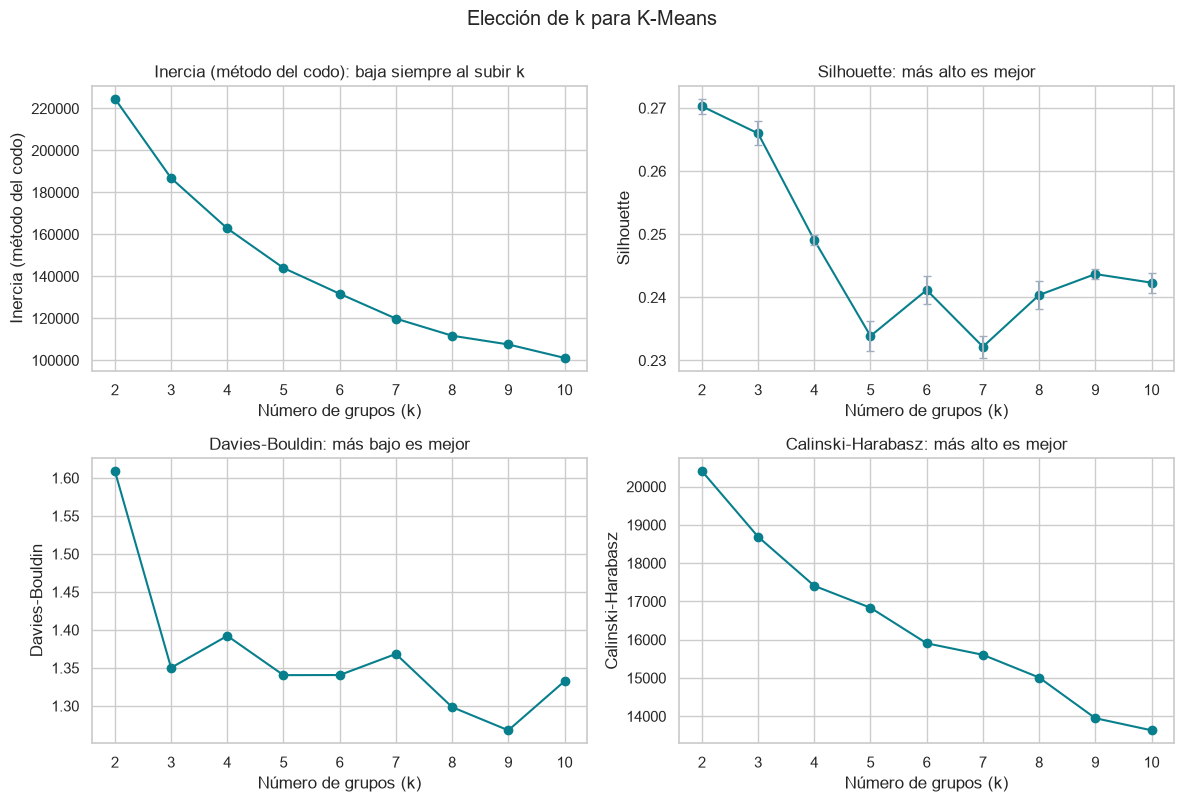

In [6]:
paneles = [
    ("inercia", "Inercia (método del codo)", "baja siempre al subir k"),
    ("Silhouette", "Silhouette", "más alto es mejor"),
    ("Davies-Bouldin", "Davies-Bouldin", "más bajo es mejor"),
    ("Calinski-Harabasz", "Calinski-Harabasz", "más alto es mejor"),
]
fig, ejes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (columna, titulo, lectura) in zip(ejes.flat, paneles):
    ax.plot(metricas_por_k.index, metricas_por_k[columna], marker="o", color=COLOR_PRINCIPAL)
    if columna == "Silhouette":
        ax.errorbar(metricas_por_k.index, metricas_por_k[columna],
                    yerr=metricas_por_k["Silhouette (desviación)"], fmt="none", color=COLOR_SECUNDARIO, capsize=3)
    ax.set_title(f"{titulo}: {lectura}")
    ax.set_xlabel("Número de grupos (k)")
    ax.set_ylabel(titulo)
    ax.set_xticks(list(VALORES_K))
plt.suptitle("Elección de k para K-Means", y=1.0)
plt.tight_layout()
plt.show()

**¿Qué vemos?**

- **No hay un codo claro.** La inercia baja 16,9 % de 2 a 3 grupos y 12,8 % de 3 a 4, y de ahí en adelante sigue bajando poco a poco (entre 3,7 % y 11,6 % por cada grupo más). No hay un punto donde la curva se doble de golpe.
- **El Silhouette es bajo para cualquier *k***: va de 0,270 con *k* = 2 a 0,232 con *k* = 7, en el borde entre "estructura débil" y "sin estructura sustancial". Las tres muestras dan casi lo mismo (desviación de 0,002 o menos), así que no es un problema de la muestra. Las reservas no forman grupos naturales bien separados: se parecen más a un continuo, que los segmentos parten en pedazos.
- **Las otras dos medidas tampoco coinciden.** Calinski-Harabasz es máximo con *k* = 2 y baja siempre. Davies-Bouldin mejora mucho de 2 a 3 grupos (de 1,609 a 1,350) y después queda entre 1,268 y 1,392 sin una tendencia clara.

Con medidas tan parejas, ninguna escoge *k* por sí sola. Los candidatos razonables son *k* = 3, que tiene casi el mismo Silhouette que *k* = 2 y un Davies-Bouldin mucho mejor, y *k* = 4, que es el siguiente en Silhouette. Para decidir entre esos dos miramos qué describen los centros, solo con las variables del agrupamiento.

In [7]:
def describir_centros(etiquetas):
    """Valores típicos de cada grupo en las unidades originales de las variables de segmentación."""
    datos = X_segmentacion.assign(grupo=etiquetas)
    descripcion = datos.groupby("grupo").agg(
        reservas=("lead_time", "size"),
        anticipacion_mediana=("lead_time", "median"),
        noches_mediana=("total_noches", "median"),
        fin_de_semana=("proporcion_fin_semana", "mean"),
        huespedes_promedio=("total_huespedes", "mean"),
        con_menores=("con_menores", "mean"),
        transient=("customer_type", lambda tipo: tipo.eq("Transient").mean()),
        canal_ta_to=("distribution_channel", lambda canal: canal.eq("TA/TO").mean()),
        canal_directo_o_corporativo=("distribution_channel", lambda canal: canal.isin(["Direct", "Corporate"]).mean()),
    )
    proporciones = ["fin_de_semana", "con_menores", "transient", "canal_ta_to", "canal_directo_o_corporativo"]
    descripcion[proporciones] = descripcion[proporciones] * 100
    return descripcion.rename(columns={columna: f"{columna} (%)" for columna in proporciones})


for k in (3, 4):
    print(f"k = {k}")
    display(describir_centros(modelos_kmeans[k].labels_).round(1))

k = 3


,reservas,anticipacion_mediana,noches_mediana,fin_de_semana (%),huespedes_promedio,con_menores (%),transient (%),canal_ta_to (%),canal_directo_o_corporativo (%)
grupo,,,,,,,,,
0,35479,98.0,4.0,25.7,2.3,15.6,86.1,88.5,11.5
1,9753,17.0,2.0,75.1,1.9,6.4,87.2,75.1,24.4
2,18119,8.0,1.0,2.4,1.7,5.4,85.7,64.4,35.2


k = 4


,reservas,anticipacion_mediana,noches_mediana,fin_de_semana (%),huespedes_promedio,con_menores (%),transient (%),canal_ta_to (%),canal_directo_o_corporativo (%)
grupo,,,,,,,,,
0,8497,14.0,2.0,77.7,1.8,4.2,87.9,73.0,26.5
1,28852,97.0,4.0,26.1,1.9,0.9,83.8,89.5,10.5
2,16156,6.0,1.0,2.1,1.7,2.3,85.9,62.2,37.3
3,9846,77.0,4.0,24.5,3.4,62.3,91.8,84.5,15.4


**¿Qué vemos?**

- Con *k* = 3, K-Means separa las reservas por anticipación y por si la estancia cae en fin de semana: un grupo grande de reservas hechas con meses de anticipación, uno de estancias de fin de semana con poca anticipación y uno de reservas de una noche entre semana con muy poca anticipación. Las reservas con menores quedan repartidas, con 15,6 % en el grupo de anticipadas.
- Con *k* = 4 se mantienen esos tres perfiles y aparece uno nuevo: **viajes con menores**, con 62,3 % de reservas con niños o bebés y 3,4 huéspedes en promedio, contra menos de 2 en los demás. Ese grupo sale de las reservas anticipadas, que quedan casi sin menores.
- En los dos casos el tipo de cliente casi no cambia de un grupo a otro (entre 84 % y 92 % de *Transient*). Es lo que esperábamos por la varianza de la 1.4: el tipo de cliente pesa poco en las distancias. El canal sí cambia algo: los grupos de poca anticipación tienen más reservas directas o corporativas.

**Decisión: *k* = 4.** Le cuesta 0,017 de Silhouette frente a *k* = 3 (0,249 contra 0,266) y tiene un Davies-Bouldin un poco peor (1,392 contra 1,350). A cambio separa un perfil que con *k* = 3 quedaba escondido y que para un hotel es claramente distinto: las familias necesitan otras habitaciones, reservan con tiempo y probablemente cancelan por razones diferentes. Como las medidas no marcan un ganador claro y las diferencias son pequeñas, preferimos el *k* que da segmentos más útiles. Con *k* = 5 o más el Silhouette queda por debajo del de *k* = 4 (entre 0,232 y 0,244).

### 2.3 El modelo con *k* = 4

In [8]:
K_ELEGIDO = 4

kmeans = modelos_kmeans[K_ELEGIDO]
segmentos_kmeans = kmeans.labels_

tamanos = pd.Series(segmentos_kmeans).value_counts().sort_index()
display(pd.DataFrame({"reservas": tamanos, "porcentaje": (tamanos / tamanos.sum() * 100).round(1)})
        .rename_axis("segmento"))
metricas_por_k.loc[[K_ELEGIDO], ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz"]].round(3)

,reservas,porcentaje
segmento,,
0,8497,13.4
1,28852,45.5
2,16156,25.5
3,9846,15.5


,Silhouette,Davies-Bouldin,Calinski-Harabasz
k,,,
4,0.249,1.392,17407.471


Para ver qué separa a los segmentos desde el punto de vista de K-Means, comparamos cada centro con la reserva promedio en la matriz que usa el algoritmo. Para las numéricas la diferencia está en desviaciones estándar (después del logaritmo, en las tres de conteo), y para las columnas en 0 y 1, en proporción.

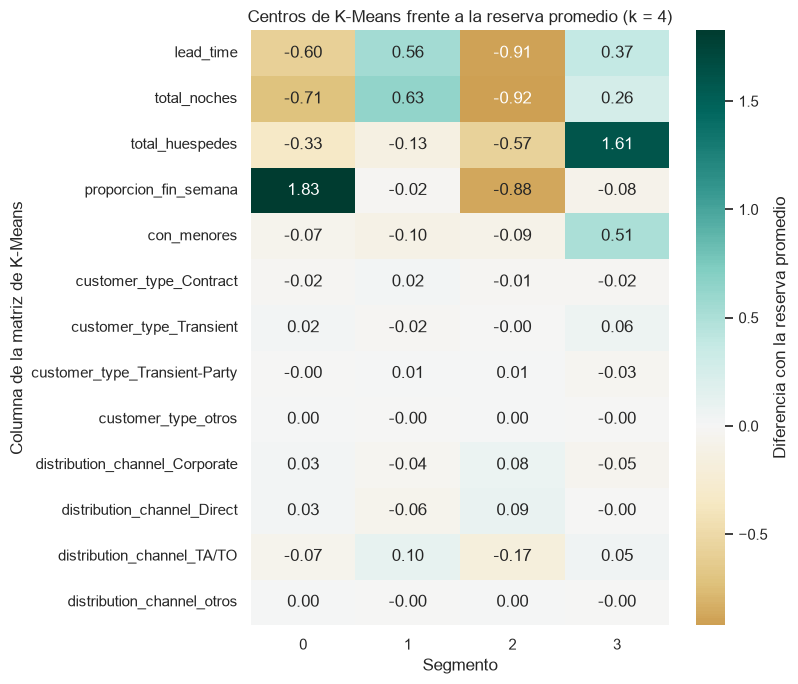

In [9]:
diferencia_centros = pd.DataFrame(
    kmeans.cluster_centers_ - Z_entrenamiento.mean(axis=0),
    columns=columnas_z,
).rename_axis("segmento")

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(diferencia_centros.T, cmap="BrBG", center=0, annot=True, fmt=".2f",
            cbar_kws={"label": "Diferencia con la reserva promedio"}, ax=ax)
ax.set_title(f"Centros de K-Means frente a la reserva promedio (k = {K_ELEGIDO})")
ax.set_xlabel("Segmento")
ax.set_ylabel("Columna de la matriz de K-Means")
plt.tight_layout()
plt.show()

**¿Qué vemos?**

- **Segmento 0 (13,4 %): estancias de fin de semana con poca anticipación.** Lo que más lo define es la proporción de noches de fin de semana, 1,83 desviaciones por encima del promedio, con menos anticipación (−0,60) y menos noches (−0,71).
- **Segmento 1 (45,5 %): reservas anticipadas y más largas.** Es el más grande. La anticipación (+0,56) y las noches (+0,63) quedan por encima del promedio, y casi no tiene menores.
- **Segmento 2 (25,5 %): última hora entre semana.** Todo queda por debajo del promedio: anticipación (−0,91), noches (−0,92) y fin de semana (−0,88). Es el que menos llega por *TA/TO* (−0,17) y el que más llega directo o por convenio corporativo.
- **Segmento 3 (15,5 %): viajes con menores.** Lo define el número de huéspedes (+1,61) y la proporción con menores, 51 puntos por encima del promedio, con algo más de anticipación y de noches que la reserva promedio.
- Las columnas del tipo de cliente no se apartan más de 0,06 del promedio en ningún segmento, y las del canal no más de 0,17. Los segmentos se arman con la anticipación, la duración, el fin de semana y el tamaño del grupo.

### 2.4 Cierre de K-Means

- Corrimos K-Means sobre las 63.351 reservas de entrenamiento con siete variables que se conocen al reservar, y escogimos *k* = 4. Las cuatro medidas no daban un ganador claro, así que decidimos entre 3 y 4 por lo que describían los segmentos, sin mirar la cancelación.
- Salieron cuatro perfiles que se entienden: estancias de fin de semana con poca anticipación (13,4 %), reservas anticipadas y más largas (45,5 %), reservas de última hora entre semana (25,5 %) y viajes con menores (15,5 %).
- El modelo tiene un Silhouette de 0,249, un Davies-Bouldin de 1,392 y un Calinski-Harabasz de 17.407. El Silhouette dice que la estructura es débil: los segmentos parten un continuo de reservas y no son tipos naturales bien separados, así que una reserva cerca de la frontera entre dos segmentos podría quedar en cualquiera de los dos.
- El tipo de cliente casi no influye en los segmentos, en parte por lo poco que pesa en las distancias (sección 1.4).

Lo que esto no permite concluir: todavía nada sobre las cancelaciones, porque no las usamos. Eso se mira en la sección 4, junto con el perfil completo de cada segmento y su estabilidad. Tampoco podemos decir que estos cuatro grupos sean los "verdaderos": con otro algoritmo o con otras variables las reservas se podrían partir distinto, y eso es justo lo que compara la sección 3.

Para la sección 3 quedan listos `crear_preparador()` y la matriz `Z_entrenamiento`, de la que el agrupamiento jerárquico puede sacar su muestra; `evaluar_agrupamiento`, para calcular las mismas medidas; y `segmentos_kmeans`, para comparar los dos métodos con el ARI.